# Phasic pupil response: single runs and run-level power vs behavior

Is the phase of the 1.25 Hz (stimulus-rate) pupil rhythm stable from trial to trial within one run, or does it drift / jump?

This notebook only **loads** what `phasic_single_run.py` saved to `derivatives/eye_tracking/phasic/<subj>/`. To compute a run:

```bash
bash run_phasic_all.sh vtc                          # every subject/run (writes batch_status_vtc.tsv)
python phasic_single_run.py sub-723 1 vtc save      # or a single run: subj, run, covariate, output mode
```

Load helpers are in [`utils_phasic.py`](utils_phasic.py). `up.show_fig` downsizes the 300-dpi PNGs and embeds them as JPEG, so the notebook stays small.

Phase convention: φ = 0 means a pupil peak at stimulus onset; peak latency within a cycle = (−φ / 2πf) mod SOA.
- **long** phase: the 16 s Hann-tapered epoch (−8 to +8 s). Neighbouring trials share ~95% of their samples, so it is smooth across trials by construction.
- **short** phase: a `short_cycles` × SOA window centred on onset of the high-passed pupil. Much less overlap, so trial-to-trial variability is visible.

In [1]:
import os, sys
import pandas as pd
sys.path.insert(0, os.getcwd())
import utils_phasic as up
pd.set_option('display.max_rows', 200, 'display.max_colwidth', 80)

## Available subjects and runs
`ok` = all figures and the summary are saved; `failed: ...` = the batch run stopped with that error; `-` = no eye-tracking/events file for that run.

In [2]:
avail = up.available_runs('vtc')
n_ok = (avail == 'ok').sum().sum()
print(f'{n_ok} runs available from {(avail == "ok").any(axis=1).sum()} subjects')
avail

44 runs available from 17 subjects


run,run-01,run-02,run-03
subj,,,
sub-629,failed: too much missing pupil data,ok,ok
sub-634,failed: too much missing pupil data,failed: too much missing pupil data,failed: too much missing pupil data
sub-636,ok,ok,ok
sub-637,ok,ok,ok
sub-642,ok,ok,ok
sub-643,failed: too much missing pupil data,failed: too much missing pupil data,failed: too much missing pupil data
sub-644,failed: too much missing pupil data,failed: too much missing pupil data,failed: too much missing pupil data
sub-661,failed: no physio/event file,failed: no physio/event file,failed: no physio/event file
sub-662,-,failed: no physio/event file,failed: no physio/event file


## Phase-locking summary, all runs
One row per run; long and short windows side by side.

In [3]:
allsum = up.load_all_summaries()
cols = ['ITPC', 'ITPC_surrogate_mean', 'p_perm', 'peak_latency_ms', 'R', 'n_non_overlapping', 'rayleigh_p']
allsum.pivot_table(index=['subj', 'run'], columns='window', values=cols).swaplevel(axis=1).sort_index(axis=1).round(3)

window        long                                                      \
              ITPC ITPC_surrogate_mean      R n_non_overlapping p_perm   
subj    run                                                              
sub-629 2    0.305               0.043  0.304              22.0  0.002   
        3    0.263               0.044  0.263              22.0  0.002   
sub-636 1    0.294               0.045  0.294              22.0  0.002   
        2    0.413               0.046  0.414              22.0  0.002   
        3    0.250               0.044  0.250              22.0  0.002   
sub-637 1    0.457               0.044  0.457              22.0  0.002   
        2    0.468               0.046  0.468              22.0  0.002   
        3    0.493               0.043  0.493              22.0  0.002   
sub-642 1    0.520               0.046  0.520              22.0  0.002   
        2    0.397               0.046  0.396              22.0  0.002   
        3    0.745               0.045  0.744              22.0  0.002   
sub-670 1    0.632               0.045  0.635              22.0  0.002   
        2    0.816               0.045  0.815              22.0  0.002   
        3    0.669               0.043  0.668              22.0  0.002   
sub-673 1    0.136               0.049  0.136              22.0  0.002   
        2    0.076               0.065  0.075              12.0  0.331   
sub-681 1    0.574               0.043  0.574              22.0  0.002   
        2    0.688               0.046  0.688              22.0  0.002   
        3    0.798               0.045  0.799              22.0  0.002   
sub-719 1    0.906               0.043  0.907              22.0  0.002   
        2    0.780               0.047  0.780              22.0  0.002   
        3    0.834               0.045  0.834              22.0  0.002   
sub-721 1    0.422               0.045  0.422              22.0  0.002   
        2    0.626               0.046  0.626              22.0  0.002   
        3    0.734               0.046  0.734              22.0  0.002   
sub-723 1    0.729               0.046  0.729              21.0  0.002   
        2    0.532               0.044  0.532              22.0  0.002   
        3    0.561               0.045  0.561              22.0  0.002   
sub-726 1    0.417               0.045  0.417              22.0  0.002   
        2    0.225               0.045  0.225              23.0  0.002   
        3    0.160               0.044  0.160              22.0  0.002   
sub-727 1    0.697               0.046  0.698              22.0  0.002   
        2    0.828               0.045  0.828              22.0  0.002   
        3    0.797               0.045  0.797              22.0  0.002   
sub-730 1    0.625               0.045  0.625              22.0  0.002   
        2    0.731               0.046  0.731              22.0  0.002   
        3    0.591               0.050  0.591              17.0  0.002   
sub-733 1    0.459               0.064  0.459              11.0  0.002   
        2    0.393               0.048  0.393              21.0  0.002   
        3    0.533               0.046  0.533              20.0  0.002   
sub-746 3    0.700               0.048  0.701              20.0  0.002   
sub-751 1    0.444               0.044  0.444              22.0  0.002   
sub-764 2    0.074               0.048  0.074              20.0  0.158   
        3    0.125               0.047  0.125              21.0  0.004   

window                                  short                             \
            peak_latency_ms rayleigh_p   ITPC ITPC_surrogate_mean      R   
subj    run                                                                
sub-629 2           685.655      0.005  0.171               0.043  0.171   
        3           657.261      0.106  0.134               0.043  0.134   
sub-636 1           259.492      0.014  0.132               0.043  0.132   
        2           223.876      0.006  0.171               0.043

## Whole-run 1.25 Hz power vs behavior (one point per run)
For each run, `phasic_single_run.py` (section 7) computes a Welch PSD of the continuous pupil over the task period (16 s Hann segments, 50% overlap) and takes:
- **power at 1.25 Hz**: the PSD bin at the run's stimulus rate (mm²/Hz)
- **SNR**: power at 1.25 Hz / mean power 0.25–0.5 Hz away (independent of pupil amplitude, so comparable across subjects)

Behavior from the events file (BIDS `response_code`: city 1 = hit, −1 = miss; mountain 0 = correct withhold, −2 = false alarm):
- **city correct** = city & code == 1; **mnt correct** = mnt & code == 0; **mnt incorrect** = mnt & code ≠ 0 (pressed)
- **mean RT** and **RT CV** over city-correct trials. RT CV = coefficient of variation = SD(RT) / mean(RT). It is unitless; it is not the variance.

In the plots each behavior metric is divided by **that subject's mean over its runs**, so every subject is centred on 1 and the x-axis shows run-to-run change within a subject (subjects with one run sit exactly at 1). Each panel's legend gives every subject's raw total (counts) or mean (RT) of that metric.

Three statistics per pair, computed on the raw (un-normalised) metrics, since runs are nested in subjects:
- **all runs**: Spearman over all runs (treats runs as independent, so p is optimistic)
- **within subject**: repeated-measures correlation (Pearson r of subject-centred values; df = runs − subjects − 1)
- **between subject**: Spearman of subject means

In [4]:
rb = up.load_run_power_behavior()
print(f"{len(rb)} runs, {rb['subj'].nunique()} subjects")
print('mean per run:', rb[['n_city_correct', 'n_city_incorrect', 'n_mnt_correct', 'n_mnt_incorrect']].mean().round(1).to_dict())
rb[['subj', 'run', 'run_power_at_f', 'run_snr', 'n_city_correct', 'n_city_incorrect', 'n_mnt_correct',
    'n_mnt_incorrect', 'rt_mean', 'rt_cv']].round(4)

44 runs, 17 subjects
mean per run: {'n_city_correct': 400.2, 'n_city_incorrect': 4.7, 'n_mnt_correct': 32.4, 'n_mnt_incorrect': 11.9}


,subj,run,run_power_at_f,run_snr,n_city_correct,n_city_incorrect,n_mnt_correct,n_mnt_incorrect,rt_mean,rt_cv
0,sub-629,2,0.0018,1.1486,399,3,22,25,0.6823,0.2772
1,sub-629,3,0.0160,0.8301,403,1,15,30,0.7076,0.3110
2,sub-636,1,0.0091,1.1693,411,0,24,14,0.6214,0.1603
3,sub-636,2,0.0048,0.8581,400,2,30,17,0.5955,0.1855
4,sub-636,3,0.0024,0.9421,403,0,28,18,0.5798,0.1615
5,sub-637,1,0.0157,1.3236,411,0,35,3,0.6933,0.1216
6,sub-637,2,0.0027,1.8847,402,0,44,3,0.6707,0.0995
7,sub-637,3,0.0046,1.5350,403,0,46,0,0.6733,0.1000
8,sub-642,1,0.0016,0.8344,404,1,29,15,0.6759,0.1912
9,sub-642,2,0.0037,1.5189,401,3,24,21,0.6524,0.2193


In [5]:
up.power_behavior_stats(rb).round(3)

n_runs  n_subj  rho_all_runs  p_all_runs  \
power          behavior                                                    
run_power_at_f n_city_correct       44      17        -0.241       0.115   
               n_mnt_correct        44      17        -0.336       0.026   
               n_mnt_incorrect      44      17         0.386       0.010   
               rt_mean              44      17         0.016       0.919   
               rt_cv                44      17         0.326       0.031   
run_snr        n_city_correct       44      17         0.101       0.514   
               n_mnt_correct        44      17         0.231       0.132   
               n_mnt_incorrect      44      17        -0.171       0.267   
               rt_mean              44      17        -0.119       0.443   
               rt_cv                44      17        -0.223       0.145   

                                r_within_subj  p_within_subj  df_within  \
power          behavior                                                   
run_power_at_f n_city_correct          -0.057          0.772         26   
               n_mnt_correct           -0.280          0.149         26   
               n_mnt_incorrect          0.212          0.280         26   
               rt_mean                  0.128          0.518         26   
               rt_cv                    0.177          0.369         26   
run_snr        n_city_correct          -0.245          0.209         26   
               n_mnt_correct           -0.049          0.804         26   
               n_mnt_incorrect          0.131          0.507         26   
               rt_mean                 -0.190          0.333         26   
               rt_cv                   -0.061          0.760         26   

                                rho_between_subj  p_between_subj  
power          behavior                                           
run_power_at_f n_city_correct             -0.363           0.152  
               n_mnt_correct              -0.396           0.115  
               n_mnt_incorrect             0.507           0.038  
               rt_mean                     0.228           0.379  
               rt_cv                       0.355           0.162  
run_snr        n_city_correct              0.184           0.479  
               n_mnt_correct               0.265           0.304  
               n_mnt_incorrect            -0.112           0.670  
               rt_mean                    -0.230           0.374  
               rt_cv                      -0.358           0.158

### Power at 1.25 Hz vs behavior
Colour = subject; runs of one subject are joined by a line (sorted by the behavior metric). Dotted line = the subject's mean (x = 1).

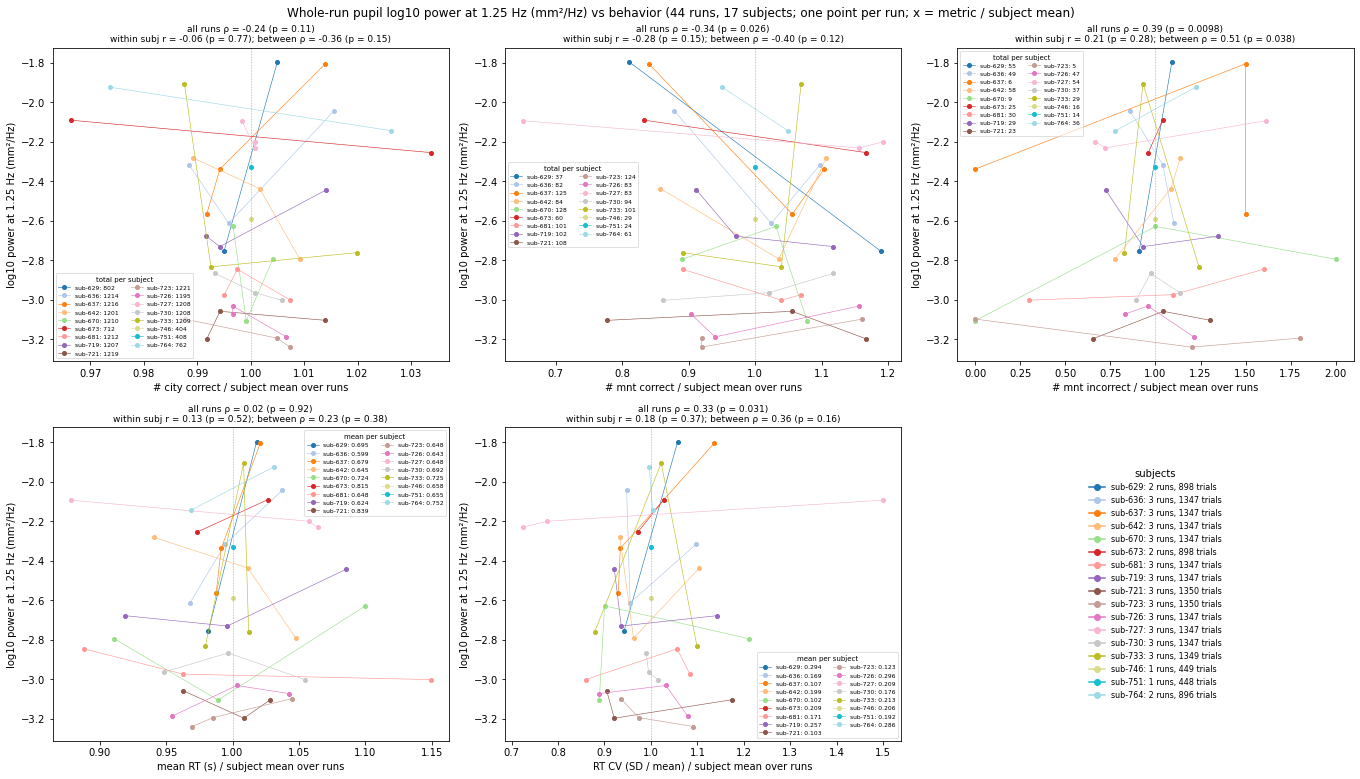

In [6]:
up.show(up.plot_power_vs_behavior(rb, 'run_power_at_f'))

### SNR at 1.25 Hz vs behavior

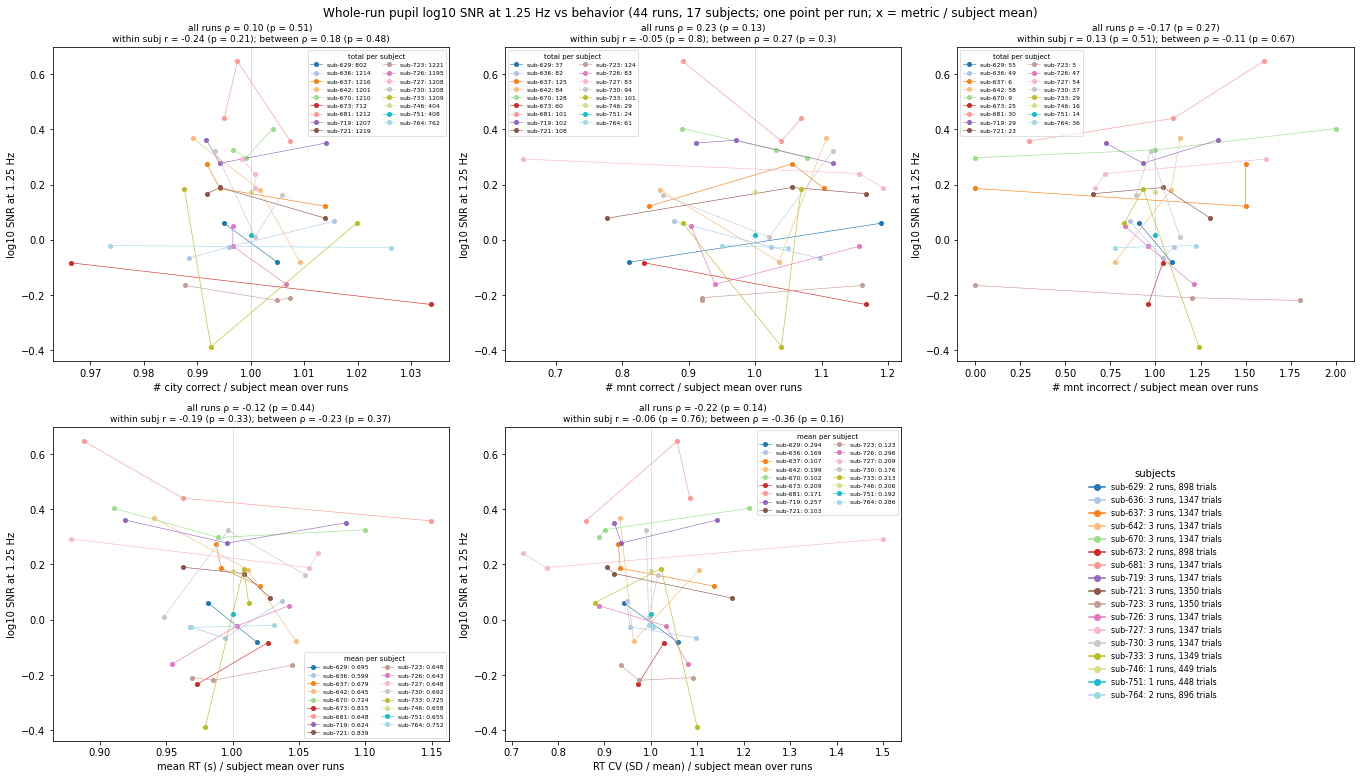

In [7]:
up.show(up.plot_power_vs_behavior(rb, 'run_snr'))

## Select one run

In [8]:
subj, run_id = 'sub-723', 1
cov_name = 'vtc'          # 'vtc', or the theta feature name (e.g. 'fz_theta_win') if run with covariate=theta

## Phase-locking summary, selected run
- **ITPC / p_perm**: onset-referenced phase vs a surrogate with reference times jittered by U(0, SOA).
- **Rayleigh**: on a subset of non-overlapping trials (independent windows).

In [9]:
up.load_summary(subj, run_id).round(4)

,label,n_trials,soa,ITPC,ITPC_surrogate_mean,p_perm,phase_re_stim_deg,peak_latency_ms,R,n_non_overlapping,rayleigh_z,rayleigh_p
window,,,,,,,,,,,,
long,16 s window,381,0.8,0.7289,0.0456,0.002,178.1833,404.0371,0.7290,21,10.9991,0.0000
short,"1.6 s window (2 cycles, high-passed)",381,0.8,0.2188,0.0463,0.002,-171.0107,380.0238,0.2188,156,9.7404,0.0001


## 1. Raster
High-passed city-correct epochs, rows in trial order (left) and sorted by the covariate (right). Vertical stripes that stay aligned down the rows = stable phase.

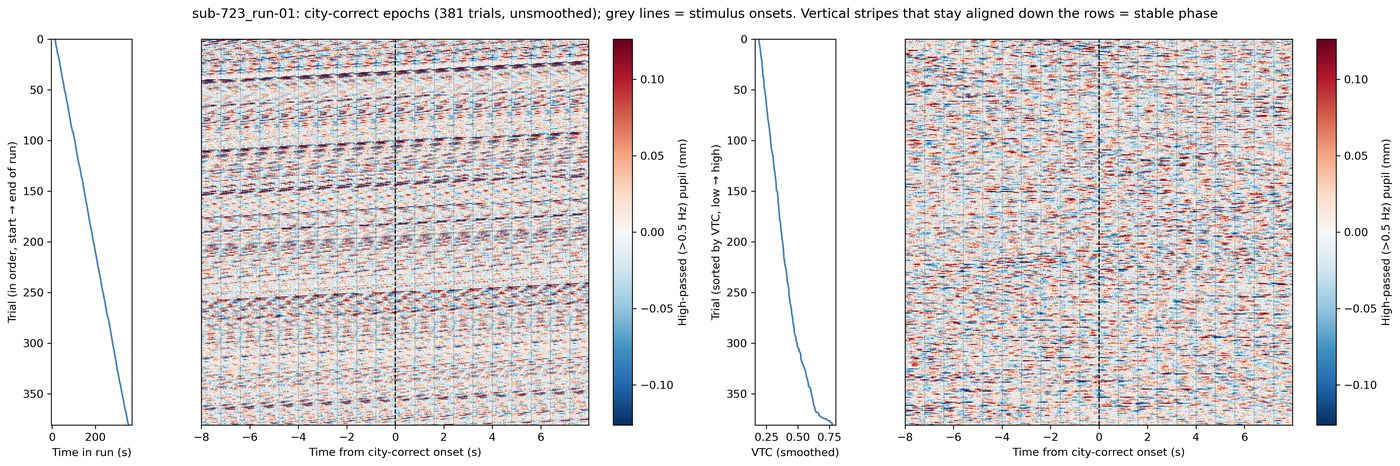

In [10]:
up.show_fig(subj, run_id, 'raster')

## 2. Spectrum
Total (mean single-trial) and evoked (trial-average) power; red lines = run stimulus rate and harmonics.

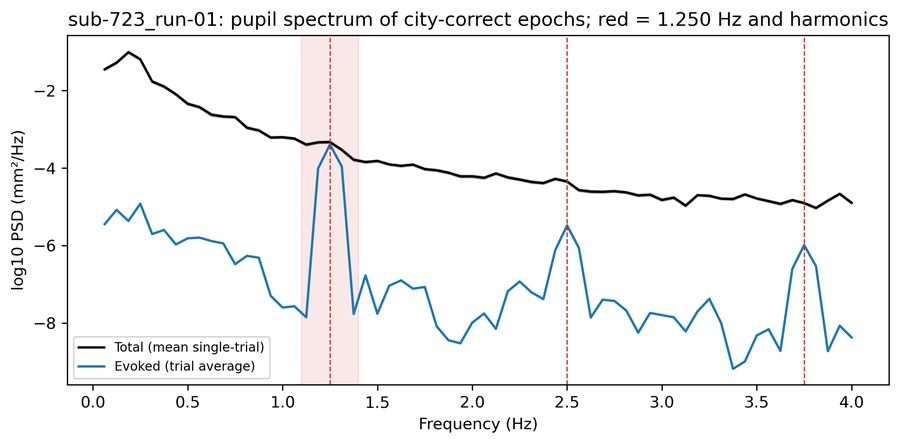

In [11]:
up.show_fig(subj, run_id, 'spectrum', width=900)

## 3. Per-trial phase across the run
Left: phase vs time in run with a sliding circular mean (black) and sliding R (orange). Middle: polar histogram. Right: observed ITPC vs shift surrogate.

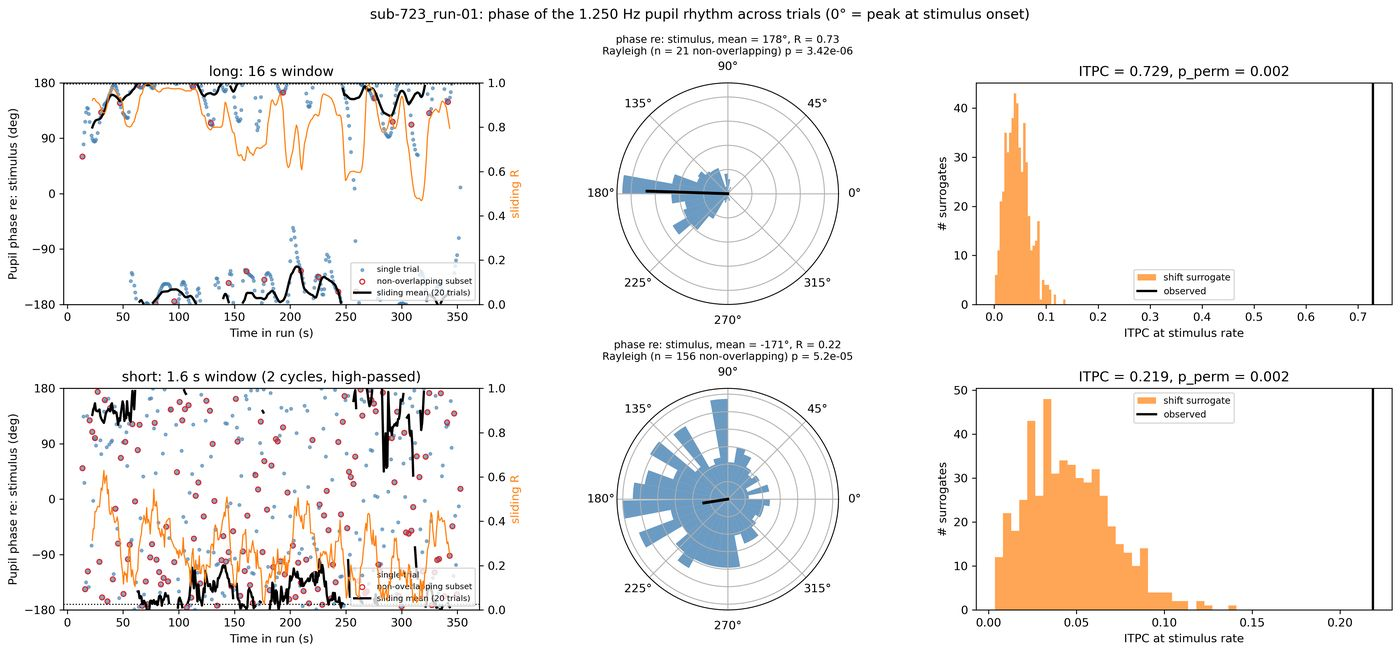

In [12]:
up.show_fig(subj, run_id, 'phase_across_trials')

## 4. Phase stability vs time separation
mean cos(φᵢ − φⱼ) over trial pairs binned by |tᵢ − tⱼ|. Dashed lines = R² of each window, the flat level expected if every trial's phase comes from the same distribution. Flat near R² = phase locked for the whole run; decaying to 0 = drift. Grey strip (0–16 s) = long windows overlap, so the black curve is trivially high there.

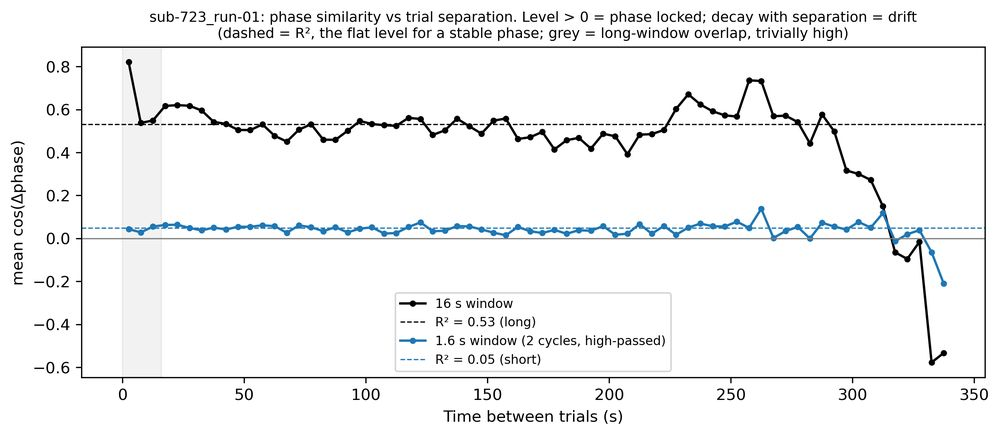

In [13]:
up.show_fig(subj, run_id, 'phase_stability_vs_lag', width=1000)

## 5. Power and phase locking vs the covariate
Trial-level; p-values are not independent because of epoch overlap.

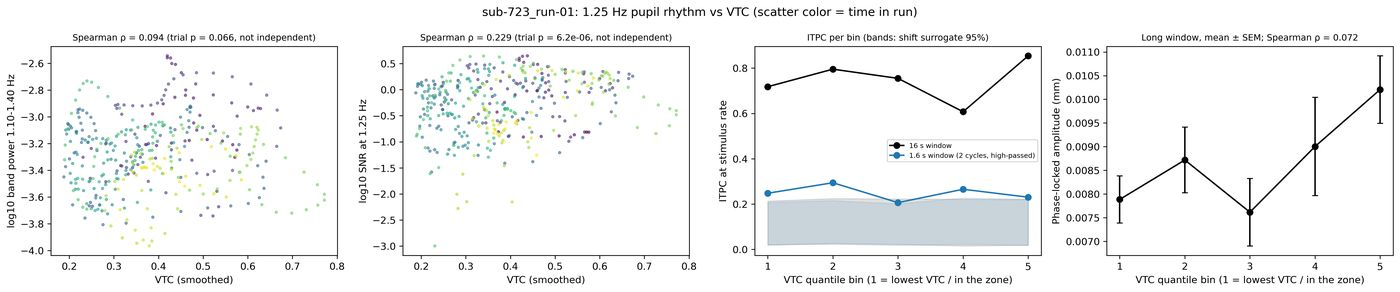

In [14]:
up.show_fig(subj, run_id, f'vs_{cov_name}')

## 6. Whole-run pupil PSD
Welch PSD used for the run-level power vs behavior analysis; red = 1.25 Hz and harmonics, shaded = band.

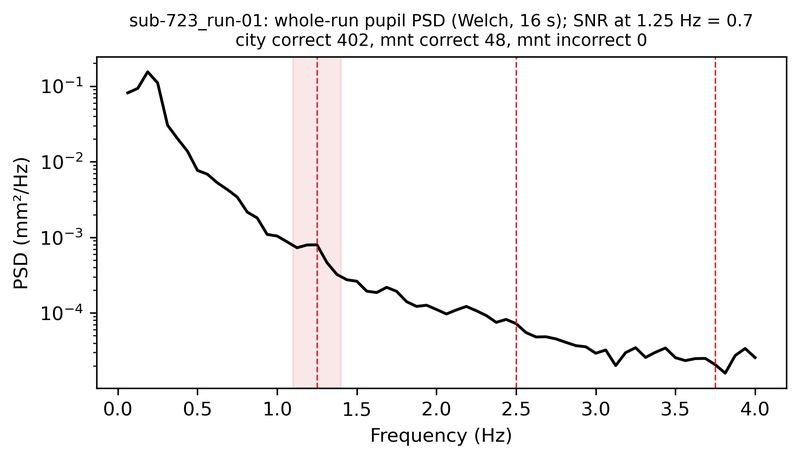

In [15]:
up.show_fig(subj, run_id, 'run_psd', width=800)